In [1]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(
"../data/sprzedaz.csv",
sep=";"
)
df.head()


,id,kanal,segment,wartosc
0,1,Internet,A,120
1,2,internet,B,250
2,3,Sklep,A,90
3,4,SKLEP,B,180
4,5,internet,A,310


In [2]:
print(df.shape)
print(df.dtypes)
print(df.isna().sum())
print(df.duplicated().sum())


(12, 4)
id         int64
kanal        str
segment      str
wartosc    int64
dtype: object
id         0
kanal      0
segment    0
wartosc    0
dtype: int64
0


In [3]:
df["wartosc"].describe()

count     12.000000
mean     187.500000
std       95.262794
min       80.000000
25%      117.500000
50%      170.000000
75%      227.500000
max      400.000000
Name: wartosc, dtype: float64

In [4]:
df["kanal"].value_counts()

kanal
internet     3
Internet     2
Sklep        2
SKLEP        2
sklep        2
internet     1
Name: count, dtype: int64

In [5]:
df["kanal"] = (
    df["kanal"]
    .str.strip()   
    .str.lower()   
)

In [6]:
licznosc_kanal = df["kanal"].value_counts()
suma_kanal = df.groupby("kanal")["wartosc"].sum()
srednia_ogolna = df["wartosc"].mean()
srednia_kanal = df.groupby("kanal")["wartosc"].mean()
mediana_ogolna = df["wartosc"].median()
mediana_kanal = df.groupby("kanal")["wartosc"].median()

In [7]:
print("=== 1. Liczba zamówień w każdym kanale ===")
print(licznosc_kanal)

print("\n=== 2. Suma wartości w każdym kanale ===")
print(suma_kanal)

print(f"\n=== 3. Średnia wartość zamówienia (ogółem): {srednia_ogolna:.2f} ===")
print("Średnia według kanału:")
print(srednia_kanal)

print(f"\n=== 4. Mediana wartości zamówienia (ogółem): {mediana_ogolna:.2f} ===")
print("Mediana według kanału:")
print(mediana_kanal)

=== 1. Liczba zamówień w każdym kanale ===
kanal
internet    6
sklep       6
Name: count, dtype: int64

=== 2. Suma wartości w każdym kanale ===
kanal
internet    1490
sklep        760
Name: wartosc, dtype: int64

=== 3. Średnia wartość zamówienia (ogółem): 187.50 ===
Średnia według kanału:
kanal
internet    248.333333
sklep       126.666667
Name: wartosc, dtype: float64

=== 4. Mediana wartości zamówienia (ogółem): 170.00 ===
Mediana według kanału:
kanal
internet    235.0
sklep       125.0
Name: wartosc, dtype: float64


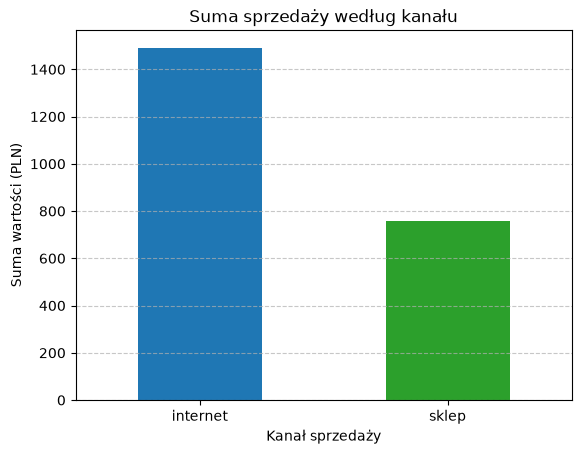

In [8]:
sprzedaz = df.groupby("kanal")["wartosc"].sum()

sprzedaz.plot(kind="bar", color=["#1f77b4", "#2ca02c"])

plt.title("Suma sprzedaży według kanału")
plt.xlabel("Kanał sprzedaży")
plt.ylabel("Suma wartości (PLN)")
plt.xticks(rotation=0)  
plt.grid(axis="y", linestyle="--", alpha=0.7)  

plt.show()

In [10]:
print ("1. Kanał internetowy wygenerował dwukrotnie większy zysk, pomimo jednakowej ilości zamówień co kanał sklep. 2.Średnia wartość zamówienia jest wyższa od mediany. Oznacza to, że pojedyncze zamówienia o wysokiej wartości zawyżają średnią, dlatego mediana może lepiej odzwierciedlać typową wartość zamówienia")

1. Kanał internetowy wygenerował dwukrotnie większy zysk, pomimo jednakowej ilości zamówień co kanał sklep. 2.Średnia wartość zamówienia jest wyższa od mediany. Oznacza to, że pojedyncze zamówienia o wysokiej wartości zawyżają średnią, dlatego mediana może lepiej odzwierciedlać typową wartość zamówienia
